In [ ]:
print("Welcome to CyberRakshak!")

Welcome to CyberRakshak!


In [ ]:

# CELL 1: ENVIRONMENT SETUP
# Purpose: Install and import the libraries required for dataset analysis, machine learning, and model saving.


# The -q option keeps installation output shorter.
!pip -q install ucimlrepo pandas scikit-learn joblib matplotlib seaborn


# SECTION 2: IMPORT LIBRARIES

# os: Work with files, folders, and file paths.Useful later when saving the trained model.
import os

# re: Regular expressions; find patterns in text.Useful later for extracting or analyzing URL patterns.
import re

# sys: Access Python interpreter and system information. We use it to check the Python version.
import sys

# joblib: Save and load trained machine learning models.
# Useful when we want to reuse our trained model without
# training it again.
import joblib

# numpy: Perform numerical calculations and work with arrays.
# Useful for numerical feature processing and ML operations.
import numpy as np

# pandas: Load, organize, filter, and analyze tabular data.
# We use DataFrames to work with the PhiUSIIL dataset.
import pandas as pd

# matplotlib.pyplot: Create graphs and charts.
# Useful for visualizing label counts and feature comparisons.
import matplotlib.pyplot as plt

# seaborn: Create statistical graphs, such as heatmaps.
# Useful later for examining relationships between features.
import seaborn as sns


# SECTION 3: VERIFY THE ENVIRONMENT

# Display the Python version currently running in Colab.
print("Python version:", sys.version)

# Display the installed pandas version.
print("Pandas version:", pd.__version__)

# Confirm that the environment setup has finished.
print("CyberRakshak environment is ready!")


# Important: This cell does NOT load the dataset or train a model.
# Those tasks will be performed in separate cells.



Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Pandas version: 2.2.3
CyberRakshak environment is ready!


In [ ]:

# CELL 2: load the dataset

# fetch_ucirepo: Fetch datasets from the UCI Machine Learning
# Repository without manually downloading the dataset.
# We use it to load the PhiUSIIL phishing URL dataset.
!pip -q install ucimlrepo
from ucimlrepo import fetch_ucirepo

# Load the PhiUSIIL phishing dataset
dataset = fetch_ucirepo(id=967)

# Combine input features and target labels
df = pd.concat(
    [dataset.data.features, dataset.data.targets],
    axis=1
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)


Dataset loaded successfully!
Dataset shape: (235795, 55)


In [ ]:
# cell 3- Basic Data Checks

print("Target label counts:")
print(df["label"].value_counts())

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())


Target label counts:
label
1    134850
0    100945
Name: count, dtype: int64

Missing values:
0

Duplicate rows:
0


In [ ]:

#cell 4 - Feature Analysis
# STEP 2: DATASET EXPLORATION
# Purpose: Understand the dataset before training an ML model



# SECTION 1: CHECK DATASET SIZE
# Rows = number of records
# Columns = number of features + target column

print("SECTION 1: DATASET SIZE")
print("-" * 40)

print("Total rows and columns:", df.shape)
print("Total records:", df.shape[0])
print("Total columns:", df.shape[1])


# SECTION 2: DISPLAY ALL COLUMN NAMES
# This helps us understand what information the dataset contains

print("\nSECTION 2: COLUMN NAMES")
print("-" * 40)

for number, column in enumerate(df.columns, start=1):
    print(number, column)


# SECTION 3: DISPLAY FIRST 3 RECORDS
# Each row represents one dataset example

print("\nSECTION 3: FIRST 3 RECORDS")
print("-" * 40)

display(df.head(3))


# SECTION 4: CHECK DATA TYPES
# int = integer, float = decimal, object = often text

print("\nSECTION 4: DATA TYPES")
print("-" * 40)

print(df.dtypes)


# ============================================================
# END OF STEP 2: DATASET EXPLORATION
# ============================================================


SECTION 1: DATASET SIZE
----------------------------------------
Total rows and columns: (235795, 55)
Total records: 235795
Total columns: 55

SECTION 2: COLUMN NAMES
----------------------------------------
1 URL
2 URLLength
3 Domain
4 DomainLength
5 IsDomainIP
6 TLD
7 URLSimilarityIndex
8 CharContinuationRate
9 TLDLegitimateProb
10 URLCharProb
11 TLDLength
12 NoOfSubDomain
13 HasObfuscation
14 NoOfObfuscatedChar
15 ObfuscationRatio
16 NoOfLettersInURL
17 LetterRatioInURL
18 NoOfDegitsInURL
19 DegitRatioInURL
20 NoOfEqualsInURL
21 NoOfQMarkInURL
22 NoOfAmpersandInURL
23 NoOfOtherSpecialCharsInURL
24 SpacialCharRatioInURL
25 IsHTTPS
26 LineOfCode
27 LargestLineLength
28 HasTitle
29 Title
30 DomainTitleMatchScore
31 URLTitleMatchScore
32 HasFavicon
33 Robots
34 IsResponsive
35 NoOfURLRedirect
36 NoOfSelfRedirect
37 HasDescription
38 NoOfPopup
39 NoOfiFrame
40 HasExternalFormSubmit
41 HasSocialNet
42 HasSubmitButton
43 HasHiddenFields
44 HasPasswordField
45 Bank
46 Pay
47 Crypto
48 HasCo

,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,0.061933,...,0,0,1,34,20,28,119,0,124,1
1,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,0.050207,...,0,0,1,50,9,8,39,0,217,1
2,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,0.064129,...,0,0,1,10,2,7,42,2,5,1



SECTION 4: DATA TYPES
----------------------------------------
URL                            object
URLLength                       int64
Domain                         object
DomainLength                    int64
IsDomainIP                      int64
TLD                            object
URLSimilarityIndex            float64
CharContinuationRate          float64
TLDLegitimateProb             float64
URLCharProb                   float64
TLDLength                       int64
NoOfSubDomain                   int64
HasObfuscation                  int64
NoOfObfuscatedChar              int64
ObfuscationRatio              float64
NoOfLettersInURL                int64
LetterRatioInURL              float64
NoOfDegitsInURL                 int64
DegitRatioInURL               float64
NoOfEqualsInURL                 int64
NoOfQMarkInURL                  int64
NoOfAmpersandInURL              int64
NoOfOtherSpecialCharsInURL      int64
SpacialCharRatioInURL         float64
IsHTTPS                 

In [ ]:

# cell 5 -  STEP 4: URL FEATURE AUDIT
# Purpose: Identify features that can be extracted from a URL


# SECTION 1: FEATURES CANDIDATES FROM THE URL STRING
# These are candidates; we will verify their definitions.

url_features = [
    "URLLength",
    "DomainLength",
    "IsDomainIP",
    "TLD",
    "TLDLength",
    "NoOfSubDomain",
    "HasObfuscation",
    "NoOfObfuscatedChar",
    "ObfuscationRatio",
    "NoOfLettersInURL",
    "LetterRatioInURL",
    "NoOfDegitsInURL",
    "DegitRatioInURL",
    "NoOfEqualsInURL",
    "NoOfQMarkInURL",
    "NoOfAmpersandInURL",
    "NoOfOtherSpecialCharsInURL",
    "SpacialCharRatioInURL",
    "IsHTTPS"
]


# SECTION 2: CHECK WHICH COLUMNS EXIST IN OUR DATASET

available_features = [
    col for col in url_features if col in df.columns
]

print("SECTION 2: URL-BASED FEATURE CANDIDATES")
print("-" * 50)

for number, feature in enumerate(available_features, start=1):
    print(f"{number}. {feature}")

print("\nTotal candidate features:", len(available_features))


# SECTION 3: SHOW EXAMPLES OF THESE FEATURES

print("\nSECTION 3: EXAMPLE VALUES")
print("-" * 50)

display(df[["URL"] + available_features].head(5))


# SECTION 4: CHECK TARGET LABELS

print("\nSECTION 4: TARGET LABELS")
print("-" * 50)

print(df["label"].value_counts())
print("\nLabel meanings must match the dataset documentation.")


SECTION 2: URL-BASED FEATURE CANDIDATES
--------------------------------------------------
1. URLLength
2. DomainLength
3. IsDomainIP
4. TLD
5. TLDLength
6. NoOfSubDomain
7. HasObfuscation
8. NoOfObfuscatedChar
9. ObfuscationRatio
10. NoOfLettersInURL
11. LetterRatioInURL
12. NoOfDegitsInURL
13. DegitRatioInURL
14. NoOfEqualsInURL
15. NoOfQMarkInURL
16. NoOfAmpersandInURL
17. NoOfOtherSpecialCharsInURL
18. SpacialCharRatioInURL
19. IsHTTPS

Total candidate features: 19

SECTION 3: EXAMPLE VALUES
--------------------------------------------------


,URL,URLLength,DomainLength,IsDomainIP,TLD,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS
0,https://www.southbankmosaics.com,31,24,0,com,3,1,0,0,0.0,18,0.581,0,0.0,0,0,0,1,0.032,1
1,https://www.uni-mainz.de,23,16,0,de,2,1,0,0,0.0,9,0.391,0,0.0,0,0,0,2,0.087,1
2,https://www.voicefmradio.co.uk,29,22,0,uk,2,2,0,0,0.0,15,0.517,0,0.0,0,0,0,2,0.069,1
3,https://www.sfnmjournal.com,26,19,0,com,3,1,0,0,0.0,13,0.500,0,0.0,0,0,0,1,0.038,1
4,https://www.rewildingargentina.org,33,26,0,org,3,1,0,0,0.0,20,0.606,0,0.0,0,0,0,1,0.030,1



SECTION 4: TARGET LABELS
--------------------------------------------------
label
1    134850
0    100945
Name: count, dtype: int64

Label meanings must match the dataset documentation.


SECTION 1: AVERAGE FEATURE VALUES
---------------------------------------------


,URLLength,DomainLength,NoOfSubDomain,NoOfQMarkInURL,IsHTTPS
label,,,,,
0,45.72,24.47,1.17,0.07,0.49
1,26.23,19.23,1.16,0.00,1.00



SECTION 2: LABEL DISTRIBUTION GRAPH
---------------------------------------------


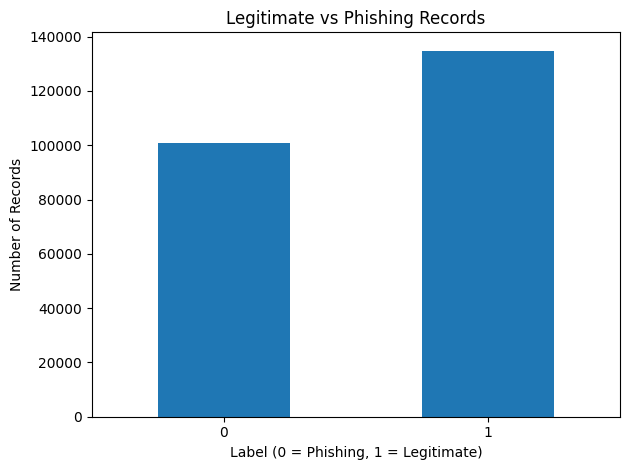

In [ ]:

# ============================================================
# CYBERRAKSHAK - STEP 5A: QUICK FEATURE ANALYSIS
# Purpose: Compare phishing and legitimate URL characteristics
# ============================================================

# SECTION 1: AVERAGE FEATURE VALUES FOR EACH LABEL

print("SECTION 1: AVERAGE FEATURE VALUES")
print("-" * 45)

features = [
    "URLLength",
    "DomainLength",
    "NoOfSubDomain",
    "NoOfQMarkInURL",
    "IsHTTPS"
]

display(df.groupby("label")[features].mean().round(2))


# SECTION 2: CREATE A CLASS DISTRIBUTION GRAPH

print("\nSECTION 2: LABEL DISTRIBUTION GRAPH")
print("-" * 45)

df["label"].value_counts().sort_index().plot(kind="bar")

plt.title("Legitimate vs Phishing Records")
plt.xlabel("Label (0 = Phishing, 1 = Legitimate)")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# ============================================================
# END OF STEP 5A
# ============================================================


CYBERRAKSHAK - STEP 5B: FEATURE ANALYSIS

*    Purpose: Compare URL features for phishing and legitimate URLs



SECTION 1: FEATURE COMPARISON
---------------------------------------------


,URLLength,DomainLength,NoOfSubDomain,NoOfQMarkInURL,IsHTTPS
label,,,,,
0,45.72,24.47,1.17,0.07,0.49
1,26.23,19.23,1.16,0.00,1.00



SECTION 2: DIFFERENCE BETWEEN LABELS
---------------------------------------------
Phishing mean - Legitimate mean:


,0
URLLength,19.49
DomainLength,5.24
NoOfSubDomain,0.01
NoOfQMarkInURL,0.07
IsHTTPS,-0.51



SECTION 3: URL LENGTH COMPARISON
---------------------------------------------


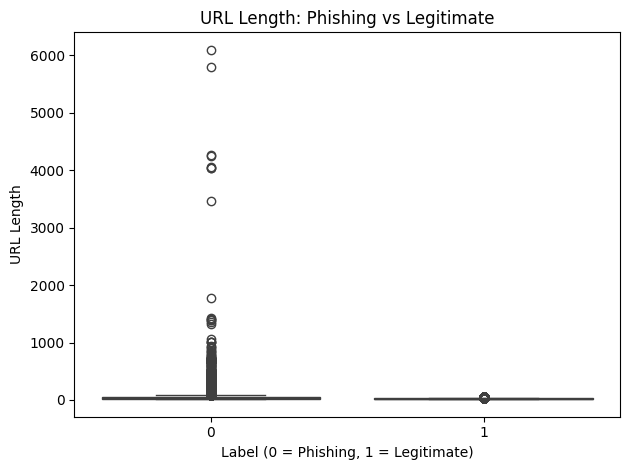

In [ ]:
# SECTION 1: COMPARE AVERAGE VALUES

features = [
    "URLLength",
    "DomainLength",
    "NoOfSubDomain",
    "NoOfQMarkInURL",
    "IsHTTPS"
]

print("SECTION 1: FEATURE COMPARISON")
print("-" * 45)

feature_comparison = df.groupby("label")[features].mean().round(2)

display(feature_comparison)


# SECTION 2: CALCULATE DIFFERENCE BETWEEN CLASSES

print("\nSECTION 2: DIFFERENCE BETWEEN LABELS")
print("-" * 45)

difference = (
    feature_comparison.loc[0] -
    feature_comparison.loc[1]
)

print("Phishing mean - Legitimate mean:")
display(difference.round(2))


# SECTION 3: VISUALISE URL LENGTH

print("\nSECTION 3: URL LENGTH COMPARISON")
print("-" * 45)

import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(
    data=df,
    x="label",
    y="URLLength"
)

plt.title("URL Length: Phishing vs Legitimate")
plt.xlabel("Label (0 = Phishing, 1 = Legitimate)")
plt.ylabel("URL Length")
plt.tight_layout()
plt.show()

In [ ]:

# ============================================================
# STEP 5C: FINAL FEATURE SELECTION
# ============================================================

# Select features that can be calculated directly from a URL
selected_features = [
    "URLLength",
    "DomainLength",
    "NoOfSubDomain",
    "NoOfQMarkInURL",
    "IsHTTPS"
]

# Store selected input features separately
X = df[selected_features]

# Store target labels
y = df["label"]

# Display the selected features
print("Selected Features:")
print(selected_features)

print("\nInput data shape:", X.shape)
print("Target data shape:", y.shape)

# Display first 5 rows of selected features
display(X.head())

# Display first 5 target labels
display(y.head())


Selected Features:
['URLLength', 'DomainLength', 'NoOfSubDomain', 'NoOfQMarkInURL', 'IsHTTPS']

Input data shape: (235795, 5)
Target data shape: (235795,)


,URLLength,DomainLength,NoOfSubDomain,NoOfQMarkInURL,IsHTTPS
0,31,24,1,0,1
1,23,16,1,0,1
2,29,22,2,0,1
3,26,19,1,0,1
4,33,26,1,0,1


,label
0,1
1,1
2,1
3,1
4,1


In [ ]:

# ============================================================
# STEP 6: TRAIN-TEST SPLIT
# ============================================================

# Import the function used to split the dataset
from sklearn.model_selection import train_test_split

# Divide the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,       # 20% data for testing
    random_state=42,      # Reproducible split
    stratify=y            # Preserve class proportions
)

# Display the sizes of each dataset
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

# Check class distribution in training and testing data
print("\nTraining label distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting label distribution:")
print(y_test.value_counts(normalize=True).round(3))


Training features: (188636, 5)
Testing features: (47159, 5)
Training labels: (188636,)
Testing labels: (47159,)

Training label distribution:
label
1    0.572
0    0.428
Name: proportion, dtype: float64

Testing label distribution:
label
1    0.572
0    0.428
Name: proportion, dtype: float64


In [ ]:
# ============================================================
# STEP 7: FEATURE SCALING
# ============================================================

# Import StandardScaler
from sklearn.preprocessing import StandardScaler

# Create the scaler object
scaler = StandardScaler()

# Fit the scaler on training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

# Display the shapes
print("Scaled training data:", X_train_scaled.shape)
print("Scaled testing data:", X_test_scaled.shape)

Scaled training data: (188636, 5)
Scaled testing data: (47159, 5)


In [ ]:

# ============================================================
# STEP 7: FINAL DATA PREPARATION
# ============================================================

import numpy as np
import pandas as pd

# Selected features from our feature-selection stage
selected_features = [
    'URLLength',
    'DomainLength',
    'NoOfSubDomain',
    'NoOfQMarkInURL',
    'IsHTTPS'
]

# Separate input features and target
X = df[selected_features].copy()
y = df['label'].copy()

# Convert feature columns to numeric values
X = X.apply(pd.to_numeric, errors='coerce')

# Remove rows containing invalid or missing values
valid_rows = X.notna().all(axis=1) & y.notna()

X = X.loc[valid_rows]
y = y.loc[valid_rows]

# Convert target labels to integers
y = y.astype(int)

print("Input shape:", X.shape)
print("Target shape:", y.shape)

print("\nClass distribution:")
print(y.value_counts())


In [ ]:

# ============================================================
# STEP 8: TRAIN-TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining class distribution:")
print(y_train.value_counts())


In [ ]:

# ============================================================
# STEP 9: MODEL TRAINING
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier

# ------------------------------------------------------------
# MODEL 1: LOGISTIC REGRESSION
# ------------------------------------------------------------

logistic_model = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

# ------------------------------------------------------------
# MODEL 2: RANDOM FOREST
# ------------------------------------------------------------

random_forest_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# ------------------------------------------------------------
# MODEL 3: EXTRA TREES
# ------------------------------------------------------------

extra_trees_model = ExtraTreesClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# Store models in a dictionary
models = {
    'Logistic Regression': logistic_model,
    'Random Forest': random_forest_model,
    'Extra Trees': extra_trees_model
}

# Train each model
for model_name, model in models.items():

    print("\nTraining:", model_name)

    model.fit(X_train, y_train)

    print("Training completed.")


In [ ]:

# ============================================================
# STEP 10: MODEL EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

results = []

for model_name, model in models.items():

    # Predict test labels
    y_pred = model.predict(X_test)

    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0
    )

    results.append({
        'Model': model_name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    })

    print("\n================================")
    print("MODEL:", model_name)
    print("================================")

    print("Accuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1 Score :", round(f1, 4))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        zero_division=0
    ))

# Display comparison table
results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON")
display(results_df.sort_values(
    by='F1 Score',
    ascending=False
))


In [ ]:

# ============================================================
# STEP 11: BEST MODEL SELECTION
# ============================================================

# Find the model with the highest F1 score
best_model_name = results_df.loc[
    results_df['F1 Score'].idxmax(),
    'Model'
]

best_model = models[best_model_name]

print("Selected Model:", best_model_name)

print("\nFinal Test Accuracy:",
      accuracy_score(y_test, best_model.predict(X_test)))

print("Final Test F1 Score:",
      f1_score(y_test, best_model.predict(X_test)))


In [ ]:

# ============================================================
# STEP 12: CONFUSION MATRIX
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Generate predictions
y_pred_best = best_model.predict(X_test)

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred_best)

print("Confusion Matrix:")
print(cm)

# Display the matrix
display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Legitimate', 'Phishing']
)

display_cm.plot()
plt.title("CyberRakshak - Confusion Matrix")
plt.show()


In [ ]:

# ============================================================
# STEP 13: FEATURE IMPORTANCE
# ============================================================

# Tree-based models provide feature_importances_
if hasattr(best_model, 'feature_importances_'):

    importance_values = best_model.feature_importances_

    importance_df = pd.DataFrame({
        'Feature': selected_features,
        'Importance': importance_values
    })

    importance_df = importance_df.sort_values(
        by='Importance',
        ascending=False
    )

    print("Feature Importance:")
    display(importance_df)

    # Plot feature importance
    plt.figure(figsize=(9, 5))

    plt.barh(
        importance_df['Feature'],
        importance_df['Importance']
    )

    plt.xlabel("Importance")
    plt.ylabel("Features")
    plt.title("CyberRakshak Feature Importance")

    plt.gca().invert_yaxis()
    plt.show()

else:
    print("The selected model does not expose tree feature importance.")


In [ ]:

# ============================================================
# STEP 14: SAVE TRAINED MODEL
# ============================================================

import joblib
import os

# Create a folder for saved model files
os.makedirs("cyberrakshak_model", exist_ok=True)

# Save model and feature information together
model_bundle = {
    'model': best_model,
    'model_name': best_model_name,
    'features': selected_features,
    'target_mapping': {
        0: 'Legitimate',
        1: 'Phishing'
    }
}

# Save the complete model bundle
joblib.dump(
    model_bundle,
    "cyberrakshak_model/cyberrakshak_phishing_model.pkl"
)

print("Model saved successfully.")


In [ ]:

# ============================================================
# STEP 15: CYBERRAKSHAK PREDICTION FUNCTION
# ============================================================

# Load the saved model bundle
loaded_bundle = joblib.load(
    "cyberrakshak_model/cyberrakshak_phishing_model.pkl"
)

loaded_model = loaded_bundle['model']
loaded_features = loaded_bundle['features']


def predict_phishing(feature_values):

    # Convert input dictionary into a DataFrame
    input_data = pd.DataFrame(
        [feature_values],
        columns=loaded_features
    )

    # Ensure values are numeric
    input_data = input_data.apply(
        pd.to_numeric,
        errors='coerce'
    )

    # Check for invalid input
    if input_data.isna().any().any():
        raise ValueError(
            "Invalid input. All five features must be numeric."
        )

    # Generate prediction
    prediction = loaded_model.predict(input_data)[0]

    # Get probability if the model supports it
    if hasattr(loaded_model, 'predict_proba'):
        probability = loaded_model.predict_proba(
            input_data
        )[0]

        confidence = float(max(probability))

    else:
        confidence = None

    # Convert numeric label into readable output
    if prediction == 1:
        result = "PHISHING"
    else:
        result = "LEGITIMATE"

    return {
        'prediction': result,
        'label': int(prediction),
        'confidence': confidence
    }


In [ ]:

# ============================================================
# STEP 16: TEST THE DETECTOR
# ============================================================

# Example feature input
sample_url_features = {
    'URLLength': 45,
    'DomainLength': 15,
    'NoOfSubDomain': 2,
    'NoOfQMarkInURL': 1,
    'IsHTTPS': 1
}

# Run prediction
prediction_result = predict_phishing(
    sample_url_features
)

print("CyberRakshak Prediction")
print("----------------------")

print("Result:",
      prediction_result['prediction'])

print("Label:",
      prediction_result['label'])

print("Confidence:",
      prediction_result['confidence'])
